# Desarrollo

Importación de librerías

Se importan las librerías necesarias para desarrollar la simulación. NumPy permite generar valores aleatorios y realizar cálculos numéricos; Pandas facilita la organización y el análisis de los datos mediante tablas; Matplotlib permite crear gráficos para visualizar los resultados.

In [ ]:
#Exprotacion de las librerias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats

print("Librerías cargadas correctamente")

Librerías cargadas correctamente


## Parámetros del problema 04
En esta celda se transcriben los datos del enunciado: proporción de retiros y pagos, probabilidades de cada tipo de usuario, tiempos promedio de servicio y entre llegadas. También se define la duración de la jornada y el número de réplicas.

In [ ]:
#-----------------------------Creacion de las tablas

# Probabilidad de cada operación
PROB_RETIRO = 0.70
PROB_PAGO = 0.30

# Tipos de usuarios
TIPOS_USUARIO = ["Rápido", "Normal", "Lento", "Muy lento"]

# Probabilidades según la operación
PROB_USUARIO_RETIRO = [0.23, 0.40, 0.17, 0.20]
PROB_USUARIO_PAGO = [0.10, 0.20, 0.30, 0.40]

# Tiempos promedio de servicio
SERVICIO_RETIRO = [1, 2, 3, 4]
SERVICIO_PAGO = [3, 3, 5, 7]

# Tiempos promedio entre llegadas
LLEGADA_RETIRO = [1, 2, 3, 3]
LLEGADA_PAGO = [1, 2, 3, 4]

# Tiempo de operación del banco
HORAS_OPERACION = 8
TIEMPO_SIMULACION = HORAS_OPERACION * 60

# Número de réplicas
NUM_REPLICAS = 10

print("Tiempo de simulación:", TIEMPO_SIMULACION, "minutos")
print("Número de réplicas:", NUM_REPLICAS)

Tiempo de simulación: 480 minutos
Número de réplicas: 10


## Generar clientes
La función selecciona la operación y la categoría de cada cliente según las probabilidades definidas. Con los valores correspondientes, genera un tiempo entre llegadas y un tiempo de servicio mediante la distribución exponencial. Se repite hasta que la hora de llegada alcanza el cierre de la jornada. El resultado es una tabla con los datos de los clientes.

In [ ]:
#Funcion que simula la llegada de los clientes
def generar_clientes_dia(seed=None):
    """
    Genera los clientes que llegan durante un día de operación de 8 horas.

    Cada cliente tiene:
    - Hora de llegada
    - Tipo de operación
    - Tipo de usuario
    - Tiempo de servicio
    """

    rng = np.random.default_rng(seed)

    clientes = []
    tiempo_llegada = 0

    while tiempo_llegada < TIEMPO_SIMULACION:

        # Seleccionar el tipo de operación
        operacion = rng.choice(
            ["Retiro", "Pago"],
            p=[PROB_RETIRO, PROB_PAGO]
        )

        # Seleccionar el tipo de usuario según la operación
        if operacion == "Retiro":

            tipo_usuario = rng.choice(
                TIPOS_USUARIO,
                p=PROB_USUARIO_RETIRO
            )

            indice = TIPOS_USUARIO.index(tipo_usuario)

            media_llegada = LLEGADA_RETIRO[indice]
            media_servicio = SERVICIO_RETIRO[indice]

        else:

            tipo_usuario = rng.choice(
                TIPOS_USUARIO,
                p=PROB_USUARIO_PAGO
            )

            indice = TIPOS_USUARIO.index(tipo_usuario)

            media_llegada = LLEGADA_PAGO[indice]
            media_servicio = SERVICIO_PAGO[indice]

        # Generar el tiempo entre llegadas
        tiempo_entre_llegadas = rng.exponential(media_llegada)

        tiempo_llegada += tiempo_entre_llegadas

        if tiempo_llegada >= TIEMPO_SIMULACION:
            break

        # Generar el tiempo de atención
        tiempo_servicio = rng.exponential(media_servicio)

        clientes.append({
            "Llegada": tiempo_llegada,
            "Operacion": operacion,
            "Tipo_usuario": tipo_usuario,
            "Servicio": tiempo_servicio
        })

    return pd.DataFrame(clientes)

## Comprobación de los clientes generados
Se ejecuta la función con una semilla de prueba. Se muestran los primeros registros y el conteo por operación y categoría, para revisar que los datos se generen y que estén dentro de las categorías definidas.

In [ ]:
#Verificacion de los primeros clientes
clientes_prueba = generar_clientes_dia(seed=42)

print("Total de clientes generados:", len(clientes_prueba))

display(clientes_prueba.head(10))

Total de clientes generados: 205


,Llegada,Operacion,Tipo_usuario,Servicio
0,7.154283,Pago,Lento,1.398971
1,11.384165,Retiro,Muy lento,12.497184
2,11.525038,Retiro,Normal,2.178047
3,15.219795,Retiro,Muy lento,0.615093
4,16.120994,Retiro,Rápido,0.412985
5,21.634905,Pago,Lento,6.135429
6,22.541544,Pago,Normal,0.231231
7,23.707585,Retiro,Lento,3.792621
8,24.629762,Retiro,Normal,1.283113
9,26.387591,Retiro,Normal,0.593894


In [ ]:
print("Clientes por operación:")
display(clientes_prueba["Operacion"].value_counts())

print("\nClientes por tipo de usuario:")
display(clientes_prueba["Tipo_usuario"].value_counts())

Clientes por operación:


,count
Operacion,
Retiro,149
Pago,56



Clientes por tipo de usuario:


,count
Tipo_usuario,
Normal,74
Muy lento,59
Rápido,37
Lento,35


## Simulación de la atención en cajeros
La función recibe la lista de clientes y la cantidad de cajeros exclusivos para retiros, exclusivos para pagos y mixtos. Los cajeros mixtos pueden atender cualquiera de las dos operaciones. Para cada cliente se determina qué cajeros son elegibles y se selecciona el que tenga menor disponibilidad. Se calcula la espera, el inicio y el final de atención, y el tiempo total en el sistema.

In [ ]:
#Simulacion de los cajeros
def simular_cajeros(clientes, cajeros_retiro, cajeros_pago,
                     cajeros_mixtos, nombre_modelo):

    total_cajeros = cajeros_retiro + cajeros_pago + cajeros_mixtos

    disponibilidad = np.zeros(total_cajeros)

    cajeros = []

    # Cajeros exclusivos para retiros
    for i in range(cajeros_retiro):
        cajeros.append({
            "Cajero": f"Cajero {len(cajeros)+1}",
            "Operacion": "Retiro"
        })

    # Cajeros exclusivos para pagos
    for i in range(cajeros_pago):
        cajeros.append({
            "Cajero": f"Cajero {len(cajeros)+1}",
            "Operacion": "Pago"
        })

    # Cajeros mixtos
    for i in range(cajeros_mixtos):
        cajeros.append({
            "Cajero": f"Cajero {len(cajeros)+1}",
            "Operacion": "Mixto"
        })

    resultados = []

    clientes = clientes.sort_values("Llegada")

    for _, cliente in clientes.iterrows():

        llegada = cliente["Llegada"]
        operacion = cliente["Operacion"]
        servicio = cliente["Servicio"]

        # Cajeros exclusivos de la operación
        if operacion == "Retiro":
            candidatos = list(range(cajeros_retiro))
        else:
            candidatos = list(
                range(cajeros_retiro,
                      cajeros_retiro + cajeros_pago)
            )

        # Agregar cajeros mixtos
        candidatos += list(
            range(cajeros_retiro + cajeros_pago,
                  total_cajeros)
        )

        # Seleccionar el cajero con menor tiempo de disponibilidad
        cajero_seleccionado = min(
            candidatos,
            key=lambda x: disponibilidad[x]
        )

        inicio_servicio = max(
            llegada,
            disponibilidad[cajero_seleccionado]
        )

        espera = inicio_servicio - llegada

        fin_servicio = inicio_servicio + servicio

        disponibilidad[cajero_seleccionado] = fin_servicio

        resultados.append({
            "Modelo": nombre_modelo,
            "Llegada": llegada,
            "Operacion": operacion,
            "Tipo_usuario": cliente["Tipo_usuario"],
            "Servicio": servicio,
            "Cajero": cajeros[cajero_seleccionado]["Cajero"],
            "Inicio_servicio": inicio_servicio,
            "Fin_servicio": fin_servicio,
            "Espera": espera,
            "Tiempo_sistema": espera + servicio
        })

    return pd.DataFrame(resultados)

## Escenarios de comparación
Se establecen cuatro configuraciones. El modelo 1 es la situación base con tres cajeros mixtos. Los modelos 2 y 3 mantienen tres cajeros, pero los distribuyen de manera exclusiva entre retiros y pagos. El modelo 4 agrega un cajero mixto para estudiar el efecto de aumentar la capacidad.

In [ ]:
#Escenarios
MODELOS = {
    "Modelo 1 - 3 cajeros mixtos": (0, 0, 3),
    "Modelo 2 - 1 retiro y 2 pagos": (1, 2, 0),
    "Modelo 3 - 2 retiros y 1 pago": (2, 1, 0),
    "Modelo 4 - 4 cajeros mixtos": (0, 0, 4)
}

for nombre, configuracion in MODELOS.items():
    print(nombre, configuracion)

Modelo 1 - 3 cajeros mixtos (0, 0, 3)
Modelo 2 - 1 retiro y 2 pagos (1, 2, 0)
Modelo 3 - 2 retiros y 1 pago (2, 1, 0)
Modelo 4 - 4 cajeros mixtos (0, 0, 4)


## Ejecución de las diez réplicas
En cada réplica se genera una jornada nueva. La misma jornada se usa para comparar todos los escenarios de esa réplica, de modo que los modelos enfrentan los mismos clientes. Los resultados de atención se guardan y luego se consolidan en dos tablas: una con los registros de cada cliente y otra con un resumen por réplica y escenario.

In [ ]:
# 10 Relicas
resultados_simulacion = []
resumen_replicas = []

for replica in range(1, NUM_REPLICAS + 1):

    # Generar clientes del día
    clientes = generar_clientes_dia(seed=replica)

    for nombre_modelo, configuracion in MODELOS.items():

        cajeros_retiro, cajeros_pago, cajeros_mixtos = configuracion

        resultados = simular_cajeros(
            clientes=clientes,
            cajeros_retiro=cajeros_retiro,
            cajeros_pago=cajeros_pago,
            cajeros_mixtos=cajeros_mixtos,
            nombre_modelo=nombre_modelo
        )

        resultados["Replica"] = replica

        resultados_simulacion.append(resultados)

        # Resumen de la réplica
        resumen_replicas.append({
            "Replica": replica,
            "Modelo": nombre_modelo,
            "Total_clientes": len(resultados),
            "Espera_promedio": resultados["Espera"].mean(),
            "Espera_maxima": resultados["Espera"].max(),
            "Tiempo_sistema_promedio": resultados["Tiempo_sistema"].mean()
        })

# Unir los resultados
df_resultados = pd.concat(
    resultados_simulacion,
    ignore_index=True
)

df_replicas = pd.DataFrame(resumen_replicas)

print("Simulaciones terminadas.")
print("Número de réplicas:", NUM_REPLICAS)
print("Número de modelos:", len(MODELOS))

display(df_replicas.head(10))

Simulaciones terminadas.
Número de réplicas: 10
Número de modelos: 4


,Replica,Modelo,Total_clientes,Espera_promedio,Espera_maxima,Tiempo_sistema_promedio
0,1,Modelo 1 - 3 cajeros mixtos,220,0.740709,6.480412,4.202406
1,1,Modelo 2 - 1 retiro y 2 pagos,220,14.100730,49.880757,17.562428
2,1,Modelo 3 - 2 retiros y 1 pago,220,3.159776,34.102977,6.621473
3,1,Modelo 4 - 4 cajeros mixtos,220,0.115242,3.939329,3.576939
4,2,Modelo 1 - 3 cajeros mixtos,227,0.353670,5.598825,3.205621
5,2,Modelo 2 - 1 retiro y 2 pagos,227,2.297177,17.610490,5.149129
6,2,Modelo 3 - 2 retiros y 1 pago,227,3.413121,36.640881,6.265072
7,2,Modelo 4 - 4 cajeros mixtos,227,0.091113,2.904525,2.943064
8,3,Modelo 1 - 3 cajeros mixtos,199,0.186832,2.745107,3.277463
9,3,Modelo 2 - 1 retiro y 2 pagos,199,3.815336,22.344845,6.905967


## Estadísticas generales por escenario
Se calculan la cantidad de clientes, la espera promedio y máxima, el tiempo promedio de servicio y el tiempo promedio que permanece un cliente en el sistema. Estas medidas permiten comparar el desempeño general de las alternativas.

In [ ]:
#Analisis de los resultados generales
estadisticas_modelos = df_resultados.groupby("Modelo").agg(
    Clientes_atendidos=("Operacion", "count"),
    Espera_promedio=("Espera", "mean"),
    Espera_maxima=("Espera", "max"),
    Servicio_promedio=("Servicio", "mean"),
    Tiempo_sistema_promedio=("Tiempo_sistema", "mean")
).reset_index()

estadisticas_modelos = estadisticas_modelos.round(2)

display(estadisticas_modelos)

,Modelo,Clientes_atendidos,Espera_promedio,Espera_maxima,Servicio_promedio,Tiempo_sistema_promedio
0,Modelo 1 - 3 cajeros mixtos,2144,0.42,8.84,3.17,3.58
1,Modelo 2 - 1 retiro y 2 pagos,2144,4.78,49.88,3.17,7.95
2,Modelo 3 - 2 retiros y 1 pago,2144,3.21,59.37,3.17,6.38
3,Modelo 4 - 4 cajeros mixtos,2144,0.08,4.38,3.17,3.24


## Cantidad de usuarios por tipo
Se contabiliza cuántos usuarios de cada categoría llegaron en cada réplica y escenario. Luego se calcula el promedio de cada categoría y se identifica la réplica que tuvo el menor conteo. Como los escenarios usan la misma demanda por réplica, estos conteos sirven para describir la llegada de clientes, no el efecto de la asignación de cajeros.

In [ ]:
#Conteo por replica
conteo_usuarios = df_resultados.groupby(
    ["Modelo", "Replica", "Tipo_usuario"]
).size().reset_index(name="Cantidad")

tabla_usuarios_replicas = conteo_usuarios.pivot_table(
    index=["Modelo", "Replica"], columns="Tipo_usuario",
    values="Cantidad", fill_value=0
).reset_index()

display(tabla_usuarios_replicas)

#Promedio de usuarios
promedio_usuarios = conteo_usuarios.groupby(
    ["Modelo", "Tipo_usuario"]
)["Cantidad"].mean().reset_index().round(2)
display(promedio_usuarios)

#Identicicar la replica menor de los usuarios
menor_cantidad_usuarios = conteo_usuarios.loc[
    conteo_usuarios.groupby(["Modelo", "Tipo_usuario"])["Cantidad"].idxmin()
].reset_index(drop=True)
print("Réplica con menor conteo para cada modelo y tipo de usuario:")
display(menor_cantidad_usuarios)
conteo_usuarios = df_resultados.groupby(
    ["Modelo", "Replica", "Tipo_usuario"]
).size().reset_index(name="Cantidad")

display(conteo_usuarios.head(20))



Tipo_usuario,Modelo,Replica,Lento,Muy lento,Normal,Rápido
0,Modelo 1 - 3 cajeros mixtos,1,39.0,55.0,82.0,44.0
1,Modelo 1 - 3 cajeros mixtos,2,44.0,60.0,87.0,36.0
2,Modelo 1 - 3 cajeros mixtos,3,55.0,43.0,68.0,33.0
3,Modelo 1 - 3 cajeros mixtos,4,42.0,45.0,69.0,33.0
4,Modelo 1 - 3 cajeros mixtos,5,45.0,52.0,80.0,41.0
5,Modelo 1 - 3 cajeros mixtos,6,31.0,61.0,71.0,39.0
6,Modelo 1 - 3 cajeros mixtos,7,50.0,56.0,72.0,64.0
7,Modelo 1 - 3 cajeros mixtos,8,40.0,46.0,67.0,38.0
8,Modelo 1 - 3 cajeros mixtos,9,46.0,57.0,84.0,36.0
9,Modelo 1 - 3 cajeros mixtos,10,44.0,68.0,91.0,30.0


,Modelo,Tipo_usuario,Cantidad
0,Modelo 1 - 3 cajeros mixtos,Lento,43.6
1,Modelo 1 - 3 cajeros mixtos,Muy lento,54.3
2,Modelo 1 - 3 cajeros mixtos,Normal,77.1
3,Modelo 1 - 3 cajeros mixtos,Rápido,39.4
4,Modelo 2 - 1 retiro y 2 pagos,Lento,43.6
5,Modelo 2 - 1 retiro y 2 pagos,Muy lento,54.3
6,Modelo 2 - 1 retiro y 2 pagos,Normal,77.1
7,Modelo 2 - 1 retiro y 2 pagos,Rápido,39.4
8,Modelo 3 - 2 retiros y 1 pago,Lento,43.6
9,Modelo 3 - 2 retiros y 1 pago,Muy lento,54.3


Réplica con menor conteo para cada modelo y tipo de usuario:


,Modelo,Replica,Tipo_usuario,Cantidad
0,Modelo 1 - 3 cajeros mixtos,6,Lento,31
1,Modelo 1 - 3 cajeros mixtos,3,Muy lento,43
2,Modelo 1 - 3 cajeros mixtos,8,Normal,67
3,Modelo 1 - 3 cajeros mixtos,10,Rápido,30
4,Modelo 2 - 1 retiro y 2 pagos,6,Lento,31
5,Modelo 2 - 1 retiro y 2 pagos,3,Muy lento,43
6,Modelo 2 - 1 retiro y 2 pagos,8,Normal,67
7,Modelo 2 - 1 retiro y 2 pagos,10,Rápido,30
8,Modelo 3 - 2 retiros y 1 pago,6,Lento,31
9,Modelo 3 - 2 retiros y 1 pago,3,Muy lento,43


,Modelo,Replica,Tipo_usuario,Cantidad
0,Modelo 1 - 3 cajeros mixtos,1,Lento,39
1,Modelo 1 - 3 cajeros mixtos,1,Muy lento,55
2,Modelo 1 - 3 cajeros mixtos,1,Normal,82
3,Modelo 1 - 3 cajeros mixtos,1,Rápido,44
4,Modelo 1 - 3 cajeros mixtos,2,Lento,44
5,Modelo 1 - 3 cajeros mixtos,2,Muy lento,60
6,Modelo 1 - 3 cajeros mixtos,2,Normal,87
7,Modelo 1 - 3 cajeros mixtos,2,Rápido,36
8,Modelo 1 - 3 cajeros mixtos,3,Lento,55
9,Modelo 1 - 3 cajeros mixtos,3,Muy lento,43


## Rendimiento de los cajeros
Se agrupan los registros por escenario y cajero para calcular cuántos clientes atendió, su tiempo promedio de servicio, la espera promedio y el tiempo total de atención. Con el promedio de servicio se identifica el cajero con menor y mayor valor observado. La comparación debe interpretarse como resultado aleatorio de la simulación, porque todos los cajeros tienen la misma velocidad definida en el enunciado.

In [ ]:
#Tiempo promdeio por cajero
estadisticas_cajeros = df_resultados.groupby(
    ["Modelo", "Cajero"]
).agg(
    Clientes_atendidos=("Servicio", "count"),
    Servicio_promedio=("Servicio", "mean"),
    Espera_promedio=("Espera", "mean"),
    Tiempo_total_servicio=("Servicio", "sum")
).reset_index()

estadisticas_cajeros = estadisticas_cajeros.round(2)

display(estadisticas_cajeros)

#Cajero mas rapido y mas lento
cajeros_validos = estadisticas_cajeros[
    estadisticas_cajeros["Clientes_atendidos"] > 0
]

cajero_mas_rapido = cajeros_validos.loc[
    cajeros_validos["Servicio_promedio"].idxmin()
]

cajero_mas_lento = cajeros_validos.loc[
    cajeros_validos["Servicio_promedio"].idxmax()
]

print("CAJERO CON MENOR TIEMPO PROMEDIO DE SERVICIO")
display(cajero_mas_rapido.to_frame().T)

print("\nCAJERO CON MAYOR TIEMPO PROMEDIO DE SERVICIO")
display(cajero_mas_lento.to_frame().T)

,Modelo,Cajero,Clientes_atendidos,Servicio_promedio,Espera_promedio,Tiempo_total_servicio
0,Modelo 1 - 3 cajeros mixtos,Cajero 1,678,3.30,0.34,2237.94
1,Modelo 1 - 3 cajeros mixtos,Cajero 2,747,3.01,0.44,2248.08
2,Modelo 1 - 3 cajeros mixtos,Cajero 3,719,3.20,0.46,2302.10
3,Modelo 2 - 1 retiro y 2 pagos,Cajero 1,1488,2.30,6.63,3425.75
4,Modelo 2 - 1 retiro y 2 pagos,Cajero 2,320,5.45,0.66,1743.72
5,Modelo 2 - 1 retiro y 2 pagos,Cajero 3,336,4.82,0.53,1618.64
6,Modelo 3 - 2 retiros y 1 pago,Cajero 1,748,2.25,0.35,1680.51
7,Modelo 3 - 2 retiros y 1 pago,Cajero 2,740,2.36,0.43,1745.24
8,Modelo 3 - 2 retiros y 1 pago,Cajero 3,656,5.13,9.61,3362.36
9,Modelo 4 - 4 cajeros mixtos,Cajero 1,530,3.22,0.10,1706.63


CAJERO CON MENOR TIEMPO PROMEDIO DE SERVICIO


,Modelo,Cajero,Clientes_atendidos,Servicio_promedio,Espera_promedio,Tiempo_total_servicio
6,Modelo 3 - 2 retiros y 1 pago,Cajero 1,748,2.25,0.35,1680.51



CAJERO CON MAYOR TIEMPO PROMEDIO DE SERVICIO


,Modelo,Cajero,Clientes_atendidos,Servicio_promedio,Espera_promedio,Tiempo_total_servicio
4,Modelo 2 - 1 retiro y 2 pagos,Cajero 2,320,5.45,0.66,1743.72


## Promedio de usuarios atendidos por cajero
La siguiente tabla resume cuántos clientes de cada tipo atiende en promedio cada cajero, considerando las diez réplicas. Se usa una tabla cruzada para facilitar la lectura y comparar la distribución de usuarios entre cajas.

In [ ]:
#Promedio de usuarios por cajero
conteo_por_cajero = df_resultados.groupby(
    ["Modelo", "Replica", "Cajero", "Tipo_usuario"]
).size().reset_index(name="Cantidad")

promedio_por_cajero = conteo_por_cajero.groupby(
    ["Modelo", "Cajero", "Tipo_usuario"]
)["Cantidad"].mean().reset_index()

tabla_cajeros = promedio_por_cajero.pivot_table(
    index=["Modelo", "Cajero"],
    columns="Tipo_usuario",
    values="Cantidad",
    fill_value=0
).reset_index()

display(tabla_cajeros.round(2))

Tipo_usuario,Modelo,Cajero,Lento,Muy lento,Normal,Rápido
0,Modelo 1 - 3 cajeros mixtos,Cajero 1,16.2,16.2,23.8,11.60
1,Modelo 1 - 3 cajeros mixtos,Cajero 2,15.2,19.8,26.5,13.20
2,Modelo 1 - 3 cajeros mixtos,Cajero 3,12.2,18.3,26.8,14.60
3,Modelo 2 - 1 retiro y 2 pagos,Cajero 1,24.5,29.1,62.6,32.60
4,Modelo 2 - 1 retiro y 2 pagos,Cajero 2,9.7,12.4,7.3,3.25
5,Modelo 2 - 1 retiro y 2 pagos,Cajero 3,9.4,12.8,7.2,4.20
6,Modelo 3 - 2 retiros y 1 pago,Cajero 1,12.9,12.2,33.2,16.50
7,Modelo 3 - 2 retiros y 1 pago,Cajero 2,11.6,16.9,29.4,16.10
8,Modelo 3 - 2 retiros y 1 pago,Cajero 3,19.1,25.2,14.5,6.80
9,Modelo 4 - 4 cajeros mixtos,Cajero 1,11.5,12.9,19.1,9.50


## Tiempo de espera por operación
Se calcula el número de clientes y los tiempos promedio y máximo de espera para retiros y pagos. La tabla ayuda a observar si una configuración favorece una operación y genera más demora para la otra.

In [ ]:
#Tiempos de espera
espera_operacion = df_resultados.groupby(
    ["Modelo", "Operacion"]
).agg(
    Clientes=("Espera", "count"),
    Espera_promedio=("Espera", "mean"),
    Espera_maxima=("Espera", "max")
).reset_index()

display(espera_operacion.round(2))

,Modelo,Operacion,Clientes,Espera_promedio,Espera_maxima
0,Modelo 1 - 3 cajeros mixtos,Pago,656,0.37,8.84
1,Modelo 1 - 3 cajeros mixtos,Retiro,1488,0.43,8.62
2,Modelo 2 - 1 retiro y 2 pagos,Pago,656,0.60,12.27
3,Modelo 2 - 1 retiro y 2 pagos,Retiro,1488,6.63,49.88
4,Modelo 3 - 2 retiros y 1 pago,Pago,656,9.61,59.37
5,Modelo 3 - 2 retiros y 1 pago,Retiro,1488,0.39,9.35
6,Modelo 4 - 4 cajeros mixtos,Pago,656,0.07,4.38
7,Modelo 4 - 4 cajeros mixtos,Retiro,1488,0.08,3.94


## Gráfico: espera promedio por escenario here
El gráfico compara el tiempo promedio de espera. La barra más baja representa el escenario que, en promedio, requiere menos tiempo de espera antes de ser atendido.

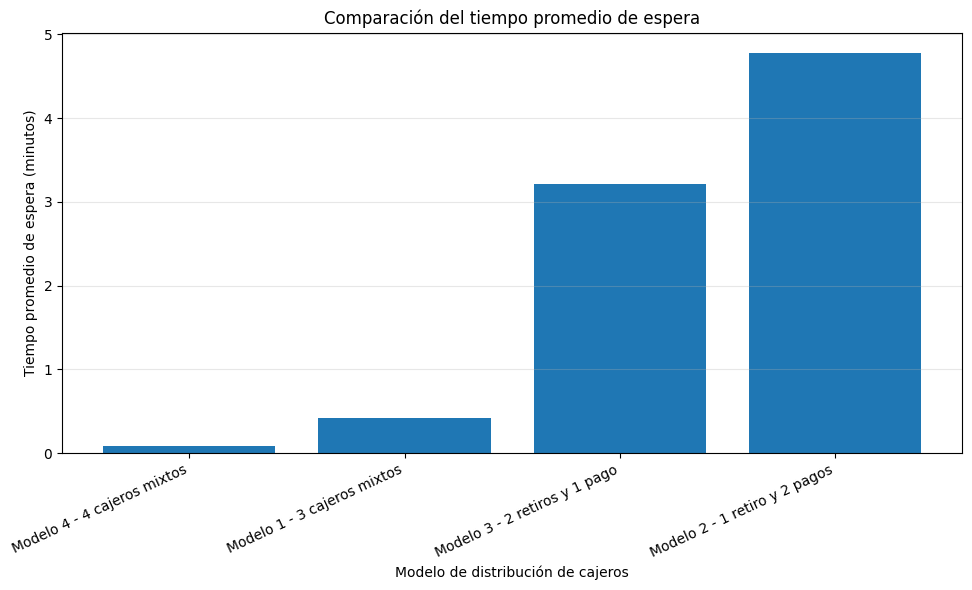

In [ ]:
#Grafico de espera promedio
plt.figure(figsize=(10, 6))

datos_grafico = estadisticas_modelos.sort_values(
    "Espera_promedio"
)

plt.bar(
    datos_grafico["Modelo"],
    datos_grafico["Espera_promedio"]
)

plt.title("Comparación del tiempo promedio de espera")
plt.xlabel("Modelo de distribución de cajeros")
plt.ylabel("Tiempo promedio de espera (minutos)")

plt.xticks(rotation=25, ha="right")

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.show()

## Gráfico: espera promedio por escenario
El gráfico compara el tiempo promedio de espera. La barra más baja representa el escenario que, en promedio, requiere menos tiempo de espera antes de ser atendido.

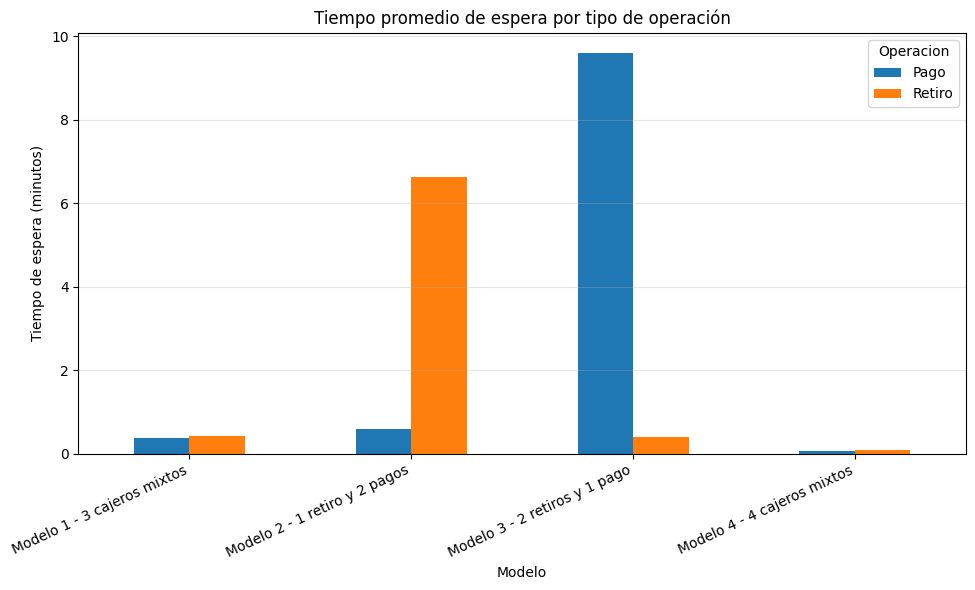

In [ ]:
# Comparacion de retiros y pagos
tabla_comparacion = espera_operacion.pivot(
    index="Modelo",
    columns="Operacion",
    values="Espera_promedio"
)

tabla_comparacion.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Tiempo promedio de espera por tipo de operación")
plt.xlabel("Modelo")
plt.ylabel("Tiempo de espera (minutos)")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()

## Evaluación de un cajero adicional
Se compara el escenario base de tres cajeros mixtos con el escenario de cuatro. Se calcula la diferencia en minutos y el porcentaje de reducción de espera. El resultado sirve como evidencia para valorar el beneficio del cajero adicional; la decisión final también debería considerar su costo.

In [ ]:
# Comparacion de los tres cajeros y el adicional
comparacion_cajeros = estadisticas_modelos[
    estadisticas_modelos["Modelo"].isin([
        "Modelo 1 - 3 cajeros mixtos",
        "Modelo 4 - 4 cajeros mixtos"
    ])
].copy()

display(comparacion_cajeros)

#Calculando la espera
espera_3 = estadisticas_modelos.loc[
    estadisticas_modelos["Modelo"] == "Modelo 1 - 3 cajeros mixtos",
    "Espera_promedio"
].values[0]

espera_4 = estadisticas_modelos.loc[
    estadisticas_modelos["Modelo"] == "Modelo 4 - 4 cajeros mixtos",
    "Espera_promedio"
].values[0]

diferencia = espera_3 - espera_4

if espera_3 != 0:
    porcentaje_reduccion = (diferencia / espera_3) * 100
else:
    porcentaje_reduccion = 0

print(f"Espera con 3 cajeros: {espera_3:.2f} minutos")
print(f"Espera con 4 cajeros: {espera_4:.2f} minutos")
print(f"Reducción de espera: {diferencia:.2f} minutos")
print(f"Reducción porcentual: {porcentaje_reduccion:.2f}%")

,Modelo,Clientes_atendidos,Espera_promedio,Espera_maxima,Servicio_promedio,Tiempo_sistema_promedio
0,Modelo 1 - 3 cajeros mixtos,2144,0.42,8.84,3.17,3.58
3,Modelo 4 - 4 cajeros mixtos,2144,0.08,4.38,3.17,3.24


Espera con 3 cajeros: 0.42 minutos
Espera con 4 cajeros: 0.08 minutos
Reducción de espera: 0.34 minutos
Reducción porcentual: 80.95%


## Distribución exclusiva de cajeros
Se comparan los escenarios de un cajero para retiros y dos para pagos, frente a dos cajeros para retiros y uno para pagos. Se revisan tanto la espera total como la espera de cada operación para determinar cuál distribución resulta más equilibrada.

In [ ]:
#Comparar distribucion de retiros y pagos
modelos_exclusivos = estadisticas_modelos[
    estadisticas_modelos["Modelo"].isin([
        "Modelo 2 - 1 retiro y 2 pagos",
        "Modelo 3 - 2 retiros y 1 pago"
    ])
].copy()

display(modelos_exclusivos)

#Espera por operacion
comparacion_exclusivos = espera_operacion[
    espera_operacion["Modelo"].isin([
        "Modelo 2 - 1 retiro y 2 pagos",
        "Modelo 3 - 2 retiros y 1 pago"
    ])
]

display(comparacion_exclusivos.round(2))

,Modelo,Clientes_atendidos,Espera_promedio,Espera_maxima,Servicio_promedio,Tiempo_sistema_promedio
1,Modelo 2 - 1 retiro y 2 pagos,2144,4.78,49.88,3.17,7.95
2,Modelo 3 - 2 retiros y 1 pago,2144,3.21,59.37,3.17,6.38


,Modelo,Operacion,Clientes,Espera_promedio,Espera_maxima
2,Modelo 2 - 1 retiro y 2 pagos,Pago,656,0.60,12.27
3,Modelo 2 - 1 retiro y 2 pagos,Retiro,1488,6.63,49.88
4,Modelo 3 - 2 retiros y 1 pago,Pago,656,9.61,59.37
5,Modelo 3 - 2 retiros y 1 pago,Retiro,1488,0.39,9.35


 ## Utilización de la capacidad
La utilización se estima como el total de minutos de servicio dividido entre los minutos de capacidad disponibles de todos los cajeros, durante las diez réplicas. Se multiplica la capacidad de un día por el número de réplicas para que el numerador y el denominador correspondan al mismo periodo. Es un indicador agregado; si la atención de clientes que llegaron antes del cierre se prolonga más allá de los 480 minutos, el tiempo de servicio puede extenderse.

In [ ]:
# Modelo de uso
utilizacion_modelos = []

for nombre_modelo, configuracion in MODELOS.items():

    cajeros_retiro, cajeros_pago, cajeros_mixtos = configuracion

    total_cajeros = (
        cajeros_retiro + cajeros_pago + cajeros_mixtos
    )

    datos = df_resultados[
        df_resultados["Modelo"] == nombre_modelo
    ]

    tiempo_total_servicio = datos["Servicio"].sum()

    capacidad_total = (
    total_cajeros * TIEMPO_SIMULACION * NUM_REPLICAS
)

    utilizacion = tiempo_total_servicio / capacidad_total

    utilizacion_modelos.append({
        "Modelo": nombre_modelo,
        "Total_cajeros": total_cajeros,
        "Tiempo_total_servicio": tiempo_total_servicio,
        "Utilizacion": utilizacion * 100
    })

tabla_utilizacion = pd.DataFrame(utilizacion_modelos)

tabla_utilizacion["Utilizacion"] = tabla_utilizacion[
    "Utilizacion"
].round(2)

display(tabla_utilizacion)

,Modelo,Total_cajeros,Tiempo_total_servicio,Utilizacion
0,Modelo 1 - 3 cajeros mixtos,3,6788.118079,47.14
1,Modelo 2 - 1 retiro y 2 pagos,3,6788.118079,47.14
2,Modelo 3 - 2 retiros y 1 pago,3,6788.118079,47.14
3,Modelo 4 - 4 cajeros mixtos,4,6788.118079,35.35


## Gráfico de utilización
Se representa la utilización estimada de cada configuración. Permite comparar la carga de trabajo con la capacidad disponible; un valor mayor indica que una proporción más alta de la capacidad se dedica a atender clientes.

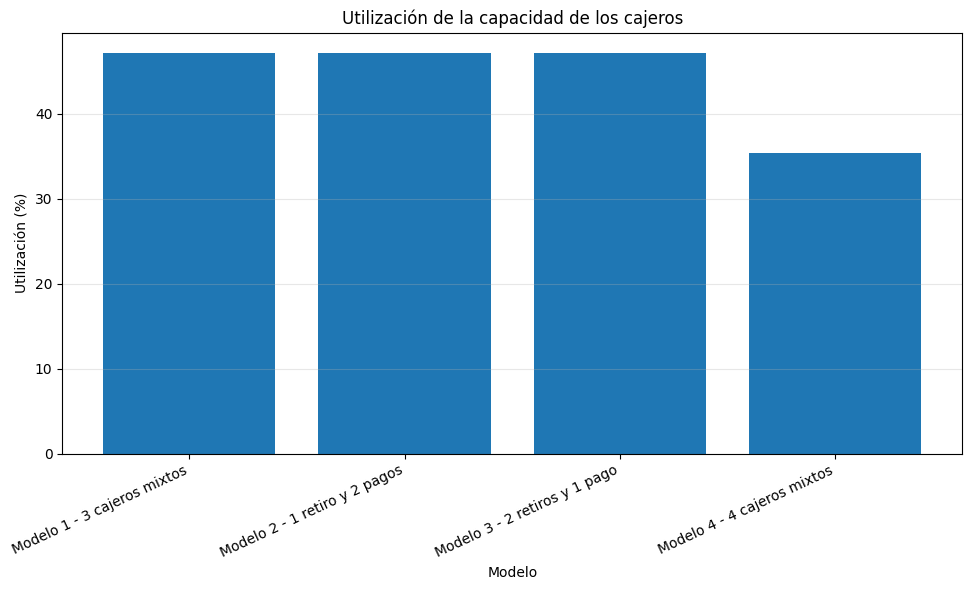

In [ ]:
# Grafico de uso
plt.figure(figsize=(10, 6))

plt.bar(
    tabla_utilizacion["Modelo"],
    tabla_utilizacion["Utilizacion"]
)

plt.title("Utilización de la capacidad de los cajeros")
plt.xlabel("Modelo")
plt.ylabel("Utilización (%)")

plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.show()

## Variabilidad entre réplicas
Se resumen las diez réplicas por escenario con la media, desviación estándar, espera mínima y máxima y promedio de clientes. La desviación estándar muestra cuánto varían los resultados de una réplica a otra, por lo que ayuda a no basar la decisión únicamente en una ejecución.

In [ ]:
#Resumen de las replicas
resumen_final_replicas = df_replicas.groupby("Modelo").agg(
    Espera_media=("Espera_promedio", "mean"),
    Desviacion_espera=("Espera_promedio", "std"),
    Espera_minima=("Espera_promedio", "min"),
    Espera_maxima=("Espera_promedio", "max"),
    Clientes_promedio=("Total_clientes", "mean")
).reset_index()

resumen_final_replicas = resumen_final_replicas.round(2)

display(resumen_final_replicas)

,Modelo,Espera_media,Desviacion_espera,Espera_minima,Espera_maxima,Clientes_promedio
0,Modelo 1 - 3 cajeros mixtos,0.41,0.21,0.11,0.74,214.4
1,Modelo 2 - 1 retiro y 2 pagos,4.68,3.63,1.66,14.10,214.4
2,Modelo 3 - 2 retiros y 1 pago,3.17,1.55,1.71,7.19,214.4
3,Modelo 4 - 4 cajeros mixtos,0.07,0.05,0.01,0.15,214.4


## Recomendacion automaticapara apoyar la decision
Esta celda identifica el escenario con menor espera promedio y muestra las comparaciones principales. La salida automática sirve como guía; la recomendación debe redactarse revisando las tablas y considerando también el equilibrio entre retiros y pagos.

In [ ]:
# Modelo con menor tiempo de espera
mejor_modelo = estadisticas_modelos.loc[
    estadisticas_modelos["Espera_promedio"].idxmin()
]

# Comparación de tres y cuatro cajeros mixtos
espera_3 = estadisticas_modelos.loc[
    estadisticas_modelos["Modelo"] == "Modelo 1 - 3 cajeros mixtos",
    "Espera_promedio"
].values[0]

espera_4 = estadisticas_modelos.loc[
    estadisticas_modelos["Modelo"] == "Modelo 4 - 4 cajeros mixtos",
    "Espera_promedio"
].values[0]

# Comparación de modelos exclusivos
espera_modelo_2 = estadisticas_modelos.loc[
    estadisticas_modelos["Modelo"] == "Modelo 2 - 1 retiro y 2 pagos",
    "Espera_promedio"
].values[0]

espera_modelo_3 = estadisticas_modelos.loc[
    estadisticas_modelos["Modelo"] == "Modelo 3 - 2 retiros y 1 pago",
    "Espera_promedio"
].values[0]

print("=" * 60)
print("RESULTADOS FINALES DE LA SIMULACIÓN BANCARIA")
print("=" * 60)

print("\nMejor modelo según espera promedio:")
print(mejor_modelo["Modelo"])

print(f"Espera promedio: {mejor_modelo['Espera_promedio']:.2f} minutos")

print("\nComparación de tres y cuatro cajeros mixtos:")
print(f"3 cajeros: {espera_3:.2f} minutos")
print(f"4 cajeros: {espera_4:.2f} minutos")

if espera_4 < espera_3:
    print("El modelo de cuatro cajeros reduce el tiempo de espera.")
else:
    print("El modelo de cuatro cajeros no presentó una reducción en la espera promedio.")

print("\nComparación de distribución exclusiva:")
print(f"1 retiro y 2 pagos: {espera_modelo_2:.2f} minutos")
print(f"2 retiros y 1 pago: {espera_modelo_3:.2f} minutos")

if espera_modelo_2 < espera_modelo_3:
    print("La distribución 1 cajero para retiros y 2 para pagos presentó menor espera.")
elif espera_modelo_3 < espera_modelo_2:
    print("La distribución 2 cajeros para retiros y 1 para pagos presentó menor espera.")
else:
    print("Ambas distribuciones presentaron el mismo tiempo promedio.")

RESULTADOS FINALES DE LA SIMULACIÓN BANCARIA

Mejor modelo según espera promedio:
Modelo 4 - 4 cajeros mixtos
Espera promedio: 0.08 minutos

Comparación de tres y cuatro cajeros mixtos:
3 cajeros: 0.42 minutos
4 cajeros: 0.08 minutos
El modelo de cuatro cajeros reduce el tiempo de espera.

Comparación de distribución exclusiva:
1 retiro y 2 pagos: 4.78 minutos
2 retiros y 1 pago: 3.21 minutos
La distribución 2 cajeros para retiros y 1 para pagos presentó menor espera.
